### Import Libraries

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.regularizers import l2
import random
from multiprocessing import Pool
import seaborn as sns
%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
import time
import math
from manim import * 

In [2]:
config.media_width = "75%"
config.verbosity = "WARNING"

### Evaluation Metrices

In [3]:
#loss and accuracy curves
def plot_static_frame(history_list, frame):
    fig, (ax_loss, ax_accuracy) = plt.subplots(1, 2, figsize=(12, 6))
    ax_loss.set_title('Training Loss')
    ax_accuracy.set_title('Training Accuracy')

    for i, history_data in enumerate(history_list):
        epochs = list(range(len(history_data['loss'])))
        ax_loss.plot(epochs[:frame], history_data['loss'][:frame])
        ax_accuracy.plot(epochs[:frame], history_data['accuracy'][:frame])

    ax_loss.set_xlabel('Epochs')
    ax_loss.set_ylabel('Loss')
    ax_accuracy.set_xlabel('Epochs')
    ax_accuracy.set_ylabel('Accuracy')
    ax_loss.legend()
    ax_accuracy.legend()

    plt.tight_layout()
    plt.show()


def animated_graph(history_list, save_as=None):
    data = history_list
    print(data)#remove this

    # Prepare the figure and axes
    fig, (ax_loss, ax_accuracy) = plt.subplots(1, 2, figsize=(12, 6))
    x = np.arange(len(data[0]['loss']))  # X-axis values (epochs)

    # Plot loss
    line_loss, = ax_loss.plot(x, data[0]['loss'], label='Loss', color='red')
    ax_loss.set_title('Training Loss')
    ax_loss.set_xlabel('Epochs')
    ax_loss.set_ylabel('Loss', color='red')

    # Calculate max values for y-limits for loss
    max_loss = max(max(d['loss']) for d in data)
    ax_loss.set_ylim(0, max_loss + 1)  # Set y-limits for loss
    ax_loss.set_xlim(0, len(x) - 1)

    # Plot accuracy
    line_accuracy, = ax_accuracy.plot(x, data[0]['accuracy'], label='Accuracy', color='blue')
    ax_accuracy.set_title('Training Accuracy')
    ax_accuracy.set_xlabel('Epochs')
    ax_accuracy.set_ylabel('Accuracy', color='blue')

    # Set specific x-ticks for accuracy
    ax_accuracy.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0])
    
    # Set specific y-limits for accuracy
    ax_accuracy.set_ylim(0.30, 0.39)  # Fixed y-limits for accuracy
    ax_accuracy.set_xlim(0, len(x) - 1)

    # Add legends
    ax_loss.legend()
    ax_accuracy.legend()

    # Animation function
    def animate(i):
        line_loss.set_ydata(data[i]['loss'])   # Update the loss line
        line_accuracy.set_ydata(data[i]['accuracy'])  # Update the accuracy line
        return line_loss, line_accuracy

    # Create animation
    ani = FuncAnimation(fig, animate, frames=len(data), interval=1000)

    if save_as:
        print(f"Animation saved as {save_as}")
        ani.save(save_as, writer=PillowWriter(fps=10))

    # Show the plot
    plt.tight_layout()
    plt.show()

#fitness trends
def plot_fitness_trends(max_fitness, avg_fitness, min_fitness, generations):
    """
    Plots the maximum, average, and minimum fitness across generations.
    """
    plt.figure(figsize=(10, 6))
    plt.plot(range(generations), max_fitness, label='Max Fitness', color='green')
    plt.plot(range(generations), avg_fitness, label='Average Fitness', color='blue')
    plt.plot(range(generations), min_fitness, label='Min Fitness', color='red')
    plt.title('Fitness Evolution')
    plt.xlabel('Generation')
    plt.ylabel('Fitness')
    plt.legend()
    plt.grid()
    plt.show()
    
#box plots
def plot_fitness_boxplot(generation_fitness):
    """
    Plots box plots for the fitness values of each generation.
    Args:
    - generation_fitness: List of lists where each sublist contains fitness values for a generation.
    """
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=generation_fitness)
    plt.title('Fitness Spread Across Generations')
    plt.xlabel('Generation')
    plt.ylabel('Fitness')
    plt.show()
#interaction analysis
#heatmaps
def plot_interaction_heatmap(interaction_matrix, character_names):
    """
    Plots a heatmap of interactions between characters.
    Args:
    - interaction_matrix: 2D array where each entry represents interaction frequency between characters.
    - character_names: List of character names.
    """
    plt.figure(figsize=(10, 8))
    sns.heatmap(interaction_matrix, annot=True, cmap='coolwarm', xticklabels=character_names, yticklabels=character_names)
    plt.title('Interaction Heatmap')
    plt.xlabel('Character')
    plt.ylabel('Character')
    plt.show()
#pie charts
def plot_action_proportions(actions):
    """
    Plots a pie chart for the proportion of actions taken.
    Args:
    - actions: List of action labels.
    """
    action_counts = {action: actions.count(action) for action in set(actions)}
    plt.figure(figsize=(8, 8))
    plt.pie(action_counts.values(), labels=action_counts.keys(), autopct='%1.1f%%', startangle=90)
    plt.title('Proportion of Actions')
    plt.show()
#population diversity
def plot_attribute_diversity(characters, generations):
    """
    Plots standard deviation of attributes across generations.
    Args:
    - characters: Nested list of Character objects across generations.
    - generations: Number of generations.
    """
    attributes = ['Strength', 'Intelligence', 'Charm', 'Composure']
    diversity = {attr: [] for attr in attributes}

    for gen in characters:
        for attr in attributes:
            diversity[attr].append(np.std([char.attributes[attr] for char in gen]))

    plt.figure(figsize=(10, 6))
    for attr, values in diversity.items():
        plt.plot(range(generations), values, label=attr)
    plt.title('Attribute Diversity Across Generations')
    plt.xlabel('Generation')
    plt.ylabel('Standard Deviation')
    plt.legend()
    plt.show()
#proximity and movement
#scatter plots
def plot_character_movements(characters):
    """
    Plots the movements of characters in the environment.
    Args:
    - characters: List of Character objects with position attributes.
    """
    plt.figure(figsize=(8, 8))
    for char in characters:
        x, y = zip(*[char.position])
        plt.scatter(x, y, label=char.name)
    plt.title('Character Movements')
    plt.xlabel('X Position')
    plt.ylabel('Y Position')
    plt.legend()
    plt.grid()
    plt.show()

#time-series plot
def plot_proximity_log(proximity_log):
    """
    Plots a time-series of proximity events.
    Args:
    - proximity_log: Dictionary with keys as interaction pairs and values as timestamps.
    """
    times = [time for time in proximity_log.values()]
    plt.figure(figsize=(10, 5))
    plt.plot(sorted(times), range(len(times)), marker='o')
    plt.title('Proximity Events Over Time')
    plt.xlabel('Time')
    plt.ylabel('Cumulative Events')
    plt.show()


### Sequential Neural Network

In [4]:
def create_character_nn(input_size=8, output_size=3):
    model = Sequential([
        Dense(64, activation='relu', input_dim=input_size, kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
        Dropout(0.3),
        Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
        Dense(output_size, activation='softmax')
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

### Fit Character with Attributes 

In [5]:
class Character:
    def __init__(self, name, motive, strength, intelligence, charm, composure, position=(0, 0)):
        self.name = name
        self.motive = motive
        self.attributes = {
            'Strength': strength,
            'Intelligence': intelligence,
            'Charm': charm,
            'Composure': composure
        }
        self.relationships = {}
        self.nn = None
        self.position = position
        
    def to_chromosome(self):
        motive_map = {'Passive': 0, 'Aggressive': 1}
        return [motive_map[self.motive]] + list(self.attributes.values())

    def from_chromosome(self, chromosome):
        motive_map = {0: 'Passive', 1: 'Aggressive'}
        try:
            self.motive = motive_map[chromosome[0]]
        except KeyError:
            print(f"Invalid motive value: {chromosome[0]}, defaulting to 'Passive'")
            self.motive = 'Passive'
        self.attributes['Strength'] = chromosome[1]
        self.attributes['Intelligence'] = chromosome[2]
        self.attributes['Charm'] = chromosome[3]
        self.attributes['Composure'] = chromosome[4]
        
    def move(self):
        self.position = (self.position[0] + random.uniform(-1, 1), 
                         self.position[1] + random.uniform(-1, 1))
    

    def make_decision(self, state):
            if self.nn:
                state = np.array(state).reshape(1, -1)
                return self.nn.predict(state)[0]
            raise AttributeError("Neural network not trained or assigned.")

### General Algorithm

In [6]:
class Individual:
    def __init__(self, chromosome):
        self.chromosome = chromosome
        self.fitness = self.cal_fitness()

    @classmethod
    def mutated_genes(cls):
        return random.randint(0, 100)

    @classmethod
    def create_gnome(cls):
        return [random.randint(0, 1)] + [random.randint(0, 100) for _ in range(4)]

    def mate(self, partner):
        child_chromosome = [
            gp1 if random.random() < 0.45 else gp2 if random.random() < 0.90 else self.mutated_genes()
            for gp1, gp2 in zip(self.chromosome, partner.chromosome)
        ]
        return Individual(child_chromosome)
        
    def cal_fitness(self):
        target_attributes = [80, 80, 80, 80]
        attribute_fitness = -sum(abs(a - b) for a, b in zip(self.chromosome[1:], target_attributes))
        return attribute_fitness

In [7]:
def calculate_population_fitness(population):
    population_matrix = np.array([ind.chromosome for ind in population])
    target = np.array([80, 80, 80, 80])
    fitness = -np.sum(np.abs(population_matrix[:, 1:] - target), axis=1)
    return fitness

def cal_fitness_parallel(population):
    with Pool(processes=min(len(population), 4)) as pool: 
        return pool.map(lambda ind: ind.cal_fitness(), population)

def tournament_selection(population, fitness, k=3):
    selected = []
    for _ in range(len(population)):
        competitors = random.sample(list(zip(population, fitness)), k)
        selected.append(max(competitors, key=lambda x: x[1])[0])
    return selected

def adaptive_mutation_rate(avg_fitness, max_fitness):
    return max(0.05, (max_fitness - avg_fitness) / max_fitness)

In [8]:
def mate_population(parents):
    offspring = []
    for i in range(0, len(parents), 2):
        if i + 1 < len(parents):
            offspring.append(parents[i].mate(parents[i + 1]))
    return offspring

### Environment with Action Logic

In [9]:
class Environment:
    def __init__(self):
        self.characters = []
        self.interactions = []

    def distance(self, char1, char2):
        x1, y1 = char1.position
        x2, y2 = char2.position
        return math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

    duration_init = time.time()
    duration_init_post = duration_init + 60*5
    def simulate(self, duration=duration_init_post, proximity_time=5):
        start_time = time.time()
        proximity_log = {}
        
        while time.time() - start_time < duration:
            characters_copy = self.characters[:]  # Work with a copy
            for char in characters_copy:
                char.move()
    
            for i, char1 in enumerate(characters_copy):
                for j in range(i + 1, len(characters_copy)):
                    char2 = characters_copy[j]
                    proximity_threshold = max(2, min(5, sum(char1.attributes.values()) // 100))
                    dist = self.distance(char1, char2)
    
                    key = frozenset([char1.name, char2.name])
                    if dist <= proximity_threshold:
                        if key not in proximity_log:
                            proximity_log[key] = time.time()
                        elif time.time() - proximity_log[key] >= proximity_time:
                            self.simulate_interaction(char1, char2)
                            del proximity_log[key]
                    elif key in proximity_log:
                        del proximity_log[key]
    
            time.sleep(1)

        print("Interactions during the simulation:")
        for interaction in self.interactions:
            print(interaction)

    def add_character(self, character):
        self.characters.append(character)
        
    def simulate_interaction(self, char1, char2):
        if char1 not in self.characters or char2 not in self.characters:
            return
        state = [char2.attributes[k] for k in ['Strength', 'Intelligence', 'Charm', 'Composure']] + \
                [char1.attributes[k] for k in ['Strength', 'Intelligence', 'Charm', 'Composure']]
        action_probs = char1.make_decision(state)
        actions = ['Make Friends', 'Killed', 'Save Another']
        action = actions[np.argmax(action_probs)]
        self.perform_action(char1, char2, action)
        self.interactions.append((char1.name, char2.name, action))
        

    def print_interactions(self):
        print("Interactions during the simulation:")
        for interaction in self.interactions:
            print(interaction)
        for character in self.characters:
            print(character.name)
        
    def perform_action(self, char1, char2, action):
        characters_to_remove = []
        print(f"{char1.name} performs {action} on {char2.name}")
        if action == 'Make Friends':
            if char1.attributes.get('Charm') > 60:
                char1.relationships[char2.name] = char1.relationships.get(char2.name, 0) + 1
            else:
                print(f'\n{char1.name} tried to become friends with {char2.name} but failed.')
        elif action == 'Killed':
            if char1 in self.characters and char2 in self.characters:
                if char1.attributes.get('Strength', 0) > char2.attributes.get('Strength', 0):
                    if char2 in self.characters:
                        self.characters.remove(char2)
                        characters_to_remove.append(char2)
                        print(f"\n{char2.name} has been removed from the environment.")
                else:
                    if char1 in self.characters:
                        self.characters.remove(char1)
                        characters_to_remove.append(char1)
                        print(f"{char1.name} has been removed from the environment.")
        elif action == 'Save Another':
            if char1 in self.characters and char2 in self.characters:
                if char1.attributes.get('Composure', 0) > char2.attributes.get('Composure',0):
                    if char2 in self.characters:
                        print(f"{char1.name} saved {char2.name}.")
                else:
                    if char1 in self.characters:
                        self.characters.remove(char2);
                        print(f"\n{char1.name} tried to save {char2.name} but failed.")
                        print(f"\n{char2.name} has been removed")

### Evolving Population

In [10]:
def evolve_population(env, generations=10, population_size=10, mutation_rate=0.1):
    max_fitness_history = []
    avg_fitness_history = []
    min_fitness_history = []
    generation_fitness = []
    characters_per_generation = []
    population = [Individual(char.to_chromosome()) for char in env.characters]
    print("Evolution Started")
    for gen in range(generations):
        # Calculate fitness
        
        fitness = calculate_population_fitness(population)
        max_fitness, avg_fitness = max(fitness), np.mean(fitness)
        min_fitness = min(fitness)
        
        # Select elite
        elite_size = max(10, population_size // 20)
        elite = sorted(zip(population, fitness), key=lambda x: x[1], reverse=True)[:elite_size]

        # Perform tournament selection
        parents = tournament_selection(population, fitness)

        # Generate offspring
        new_generation = [ind for ind, _ in elite]
        new_generation.extend(mate_population(parents))

        # Apply mutation
        for ind in new_generation[elite_size:]:
            if random.random() < adaptive_mutation_rate(avg_fitness, max_fitness):
                ind.chromosome[random.randint(0, len(ind.chromosome) - 1)] = Individual.mutated_genes()

        # Truncate population
        population = new_generation[:population_size]

        # if gen > 5 and max_fitness - min(fitness) < 1e-3:
        #     print(f"Converged at generation {gen}")
        #     break
        characters_per_generation.append(env.characters)
        generation_fitness.append(fitness)
        max_fitness_history.append(max_fitness)
        avg_fitness_history.append(avg_fitness)
        min_fitness_history.append(min_fitness)
        if max_fitness - min(fitness) < 1e-5:
            print(f"Converged at generation {gen}")
            break
    plot_attribute_diversity(characters_per_generation, generations)
    plot_fitness_trends(max_fitness_history, avg_fitness_history, min_fitness_history, generations)
    plot_fitness_boxplot(generation_fitness)
    # Update characters
    for char, individual in zip(env.characters, population):
        print("Characters updated")
        try:
            char.from_chromosome(individual.chromosome)
        except KeyError as e:
            print(f"Error in chromosome: {individual.chromosome}")
            raise e


### Generating Training Data

In [11]:
def generate_training_data():
    X = np.random.rand(1000, 8)
    y = tf.keras.utils.to_categorical(np.random.randint(3, size=(1000, 1)), num_classes=3)
    return X, y
    

### Training Characters

In [12]:
history_list = []  # Define history_list outside the function

def train_character_nn(character, X, y):
    # Fit the model for the character
    history = character.nn.fit(X, y, epochs=10, batch_size=32, verbose=0)
    
    # Collect the training history data
    history_data = {
        "loss": history.history["loss"],
        "accuracy": history.history["accuracy"]
    }
    if 'val_loss' in history.history:
        history_data['val_loss'] = history.history['val_loss']
    if 'val_accuracy' in history.history:
        history_data['val_accuracy'] = history.history['val_accuracy']
    
    # Append this character's history to the global history_list
    history_list.append(history_data)
def train_all_characters(env, X, y):
    print("Training characters' neural networks...")
    for character in env.characters:
        character.nn = create_character_nn()
        train_character_nn(character, X, y)
        
        
    print("Training completed for all characters.\n")
    plot_static_frame(history_list, frame=5)
    animated_graph(history_list,save_as="Test31.gif")

### Visualization of Character Traits

In [13]:
def visualize_characters(environment):
    names = [char.name for char in environment.characters]
    attributes = [list(char.attributes.values()) for char in environment.characters]
    plt.figure(figsize=(10, 6))
    for i, attr in enumerate(['Strength', 'Intelligence', 'Charm', 'Composure']):
        plt.bar(names, [attributes[j][i] for j in range(len(environment.characters))], label=attr)
    plt.xticks(rotation=90)  
    plt.legend()
    plt.tight_layout()  
    plt.show()

### Simulation

In [14]:
def simulate_all_interactions(env):
    interaction_matrix = np.zeros((len(env.characters), len(env.characters)))
    character_names = [char.name for char in env.characters]  # List of character names for indexing
    
    for i, char1 in enumerate(env.characters):
        for j, char2 in enumerate(env.characters):
            if char1 != char2:
                env.simulate_interaction(char1, char2)
                interaction_matrix[i][j] += 1
                interaction_matrix[j][i] += 1
                
    plot_interaction_heatmap(interaction_matrix, character_names)


### Application Runtime

Initializing environment and characters...
Characters added to environment.

Training characters' neural networks...


C:\Users\xebra\AppData\Local\Programs\Python\Python39\lib\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training completed for all characters.



C:\Users\xebra\AppData\Local\Temp\ipykernel_17484\4222701715.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_loss.legend()
C:\Users\xebra\AppData\Local\Temp\ipykernel_17484\4222701715.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax_accuracy.legend()


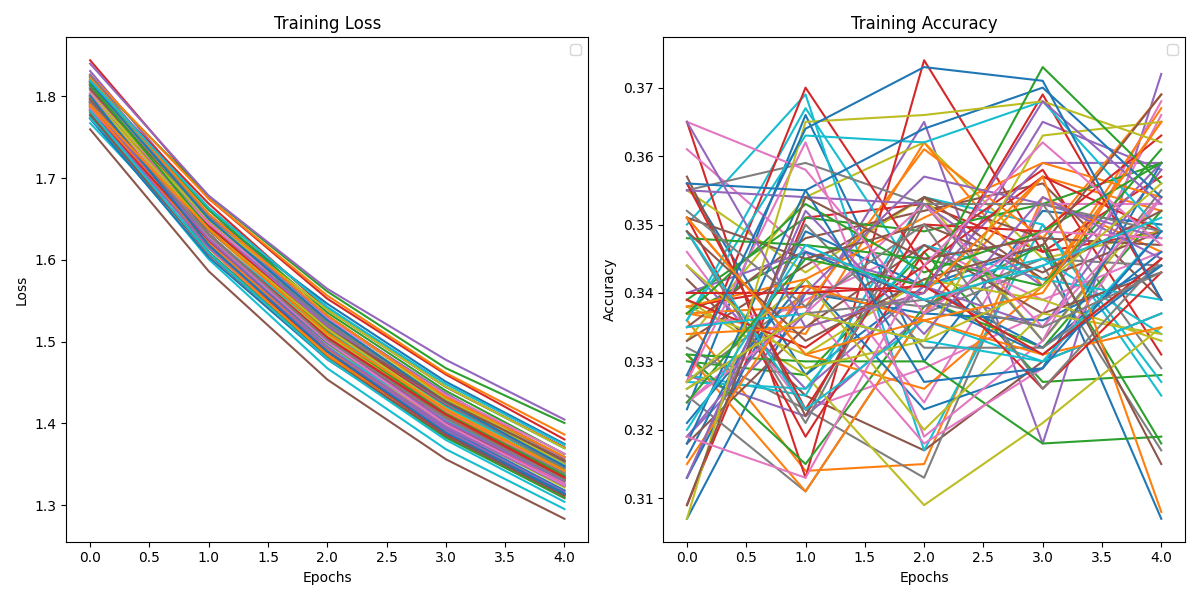

[{'loss': [1.7996022701263428, 1.6306153535842896, 1.5052564144134521, 1.4084861278533936, 1.3371434211730957, 1.280479073524475, 1.2370684146881104, 1.2045975923538208, 1.1792006492614746, 1.1606591939926147], 'accuracy': [0.3230000138282776, 0.3659999966621399, 0.33000001311302185, 0.35199999809265137, 0.3499999940395355, 0.35899999737739563, 0.34599998593330383, 0.35499998927116394, 0.3619999885559082, 0.3479999899864197]}, {'loss': [1.813665747642517, 1.639564037322998, 1.5148049592971802, 1.4138530492782593, 1.3447602987289429, 1.2879022359848022, 1.2470369338989258, 1.2161914110183716, 1.1913084983825684, 1.1728179454803467], 'accuracy': [0.335999995470047, 0.3140000104904175, 0.3149999976158142, 0.3540000021457672, 0.34599998593330383, 0.3700000047683716, 0.35199999809265137, 0.3479999899864197, 0.3370000123977661, 0.33500000834465027]}, {'loss': [1.776946783065796, 1.6191073656082153, 1.490917682647705, 1.3984707593917847, 1.326586127281189, 1.2720167636871338, 1.22958040237426

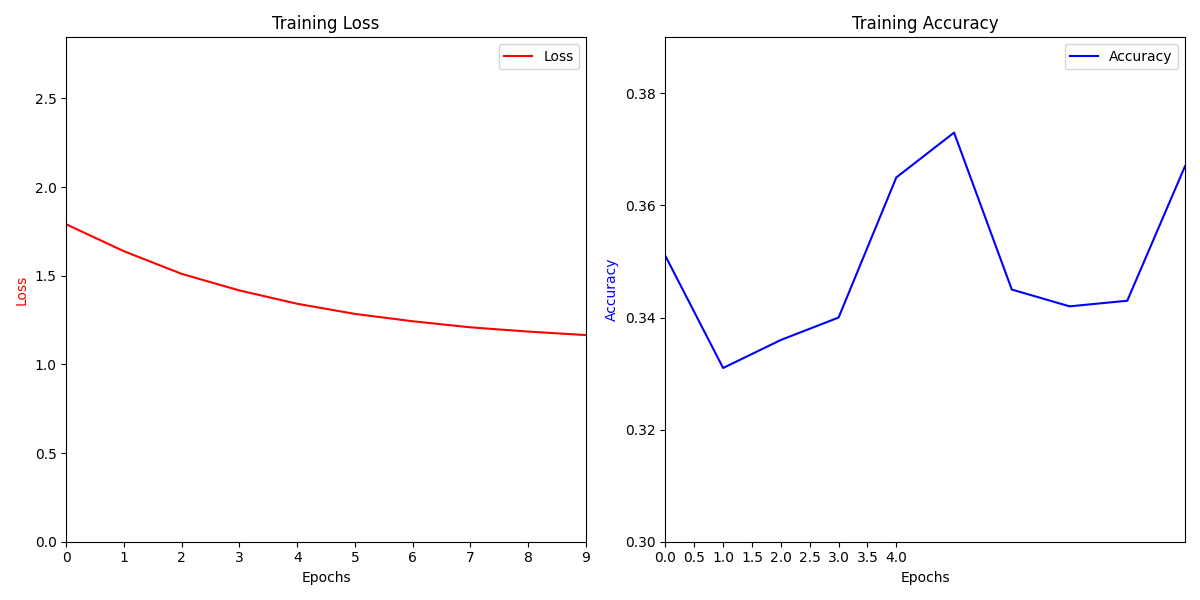

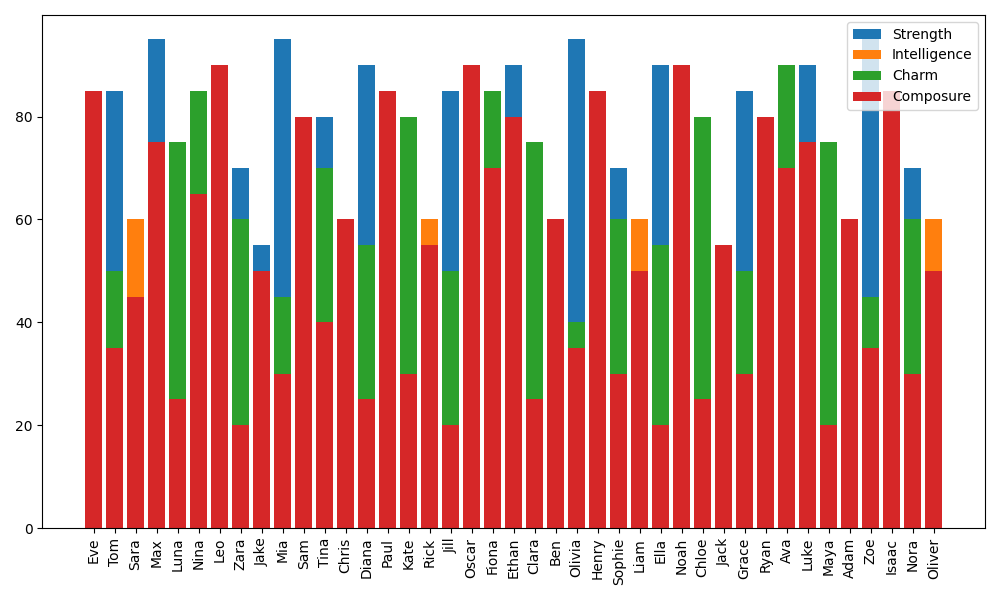


Evolving population...

Evolution Started


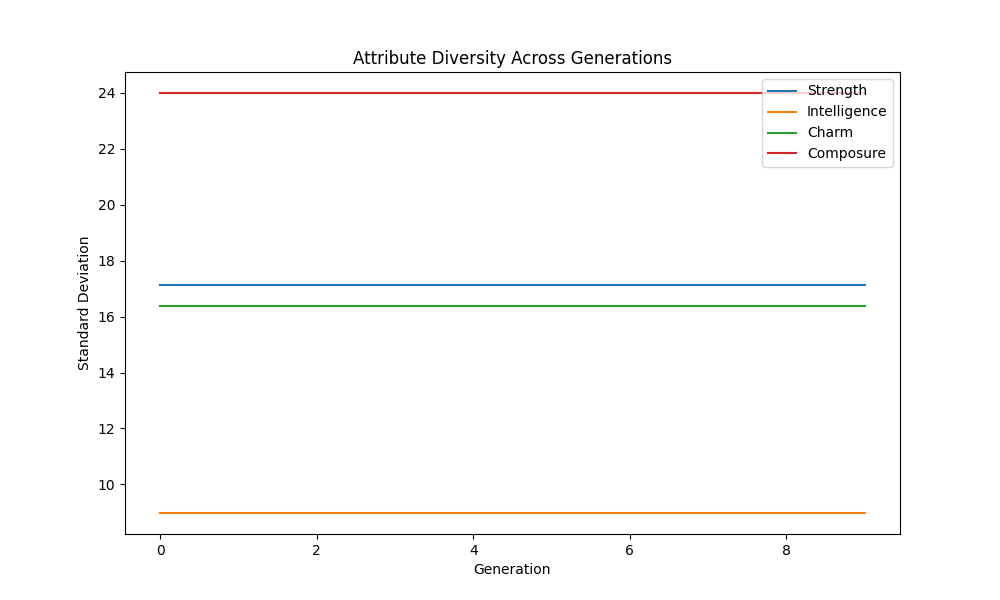

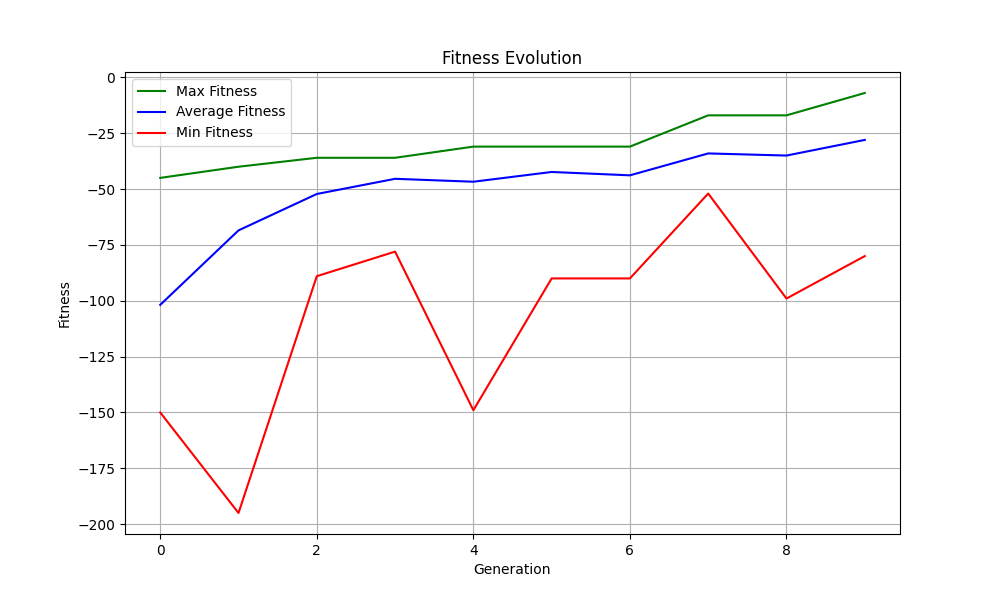

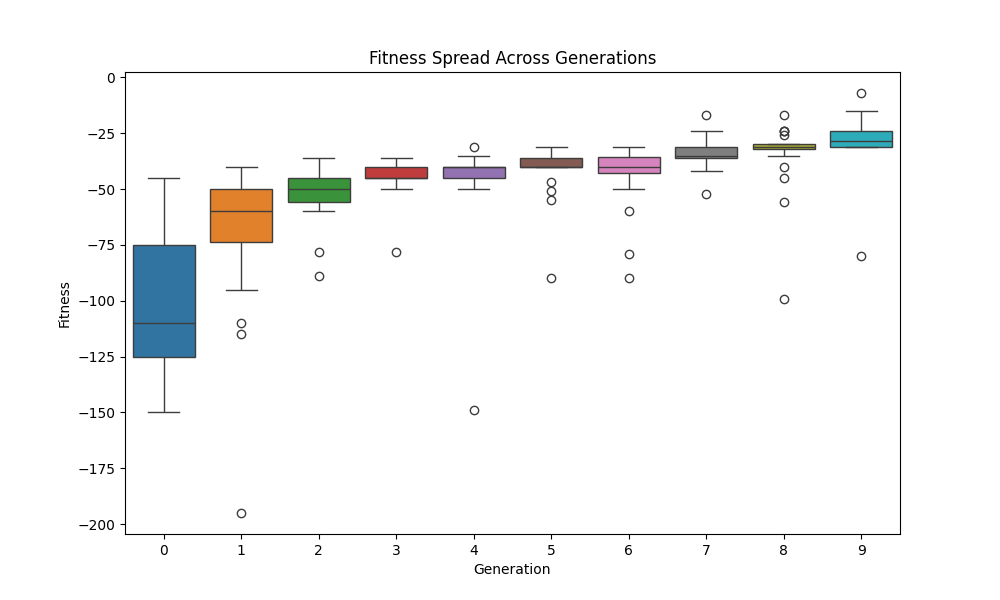

Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Invalid motive value: 17, defaulting to 'Passive'
Characters updated
Invalid motive value: 17, defaulting to 'Passive'
Characters updated
Invalid motive value: 31, defaulting to 'Passive'
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Characters updated
Starting simulation...


Simulating all interactions...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step
Eve performs Make Friends on Sam
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
Eve performs Make Friends on Henry
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
Tom performs Make Friends on Leo
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step
Tom performs Make Friends on Kate
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
Tom performs Make Friends on Grace
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
Tom performs 

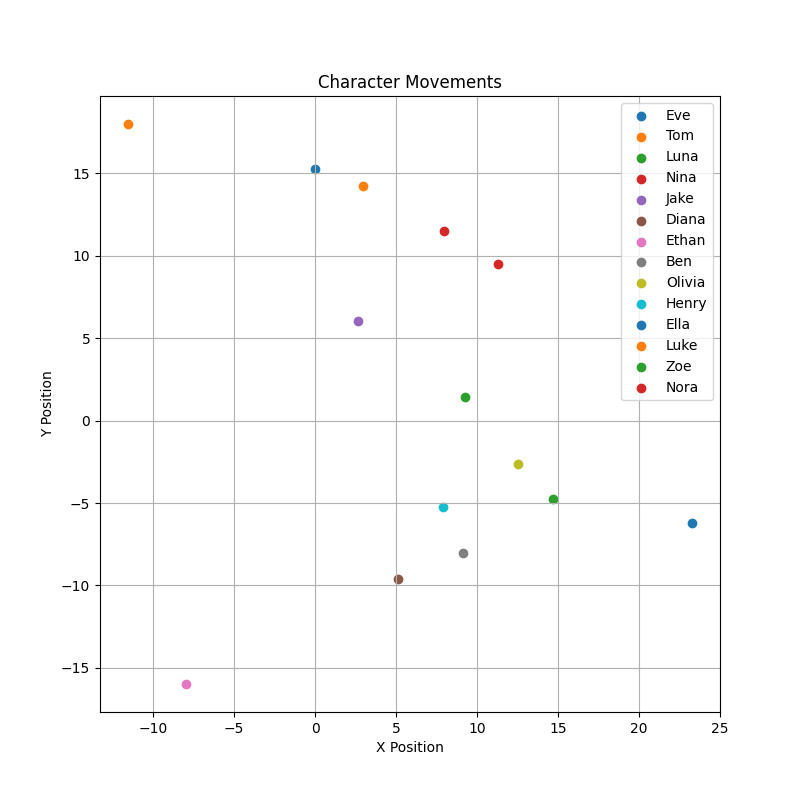

In [22]:
print("Initializing environment and characters...")
env = Environment()
characters = [
    Character('Eve', 'Passive', 75, 55, 65, 85,position=(0, 0)),
    Character('Tom', 'Aggressive', 85, 45, 50, 35,position=(5, 5)),
    Character('Sara', 'Passive', 50, 60, 30, 45,position=(5, 5)),
    Character('Max', 'Passive', 95, 35, 70, 75,position=(10, 0)),
    Character('Luna', 'Aggressive', 65, 50, 75, 25,position=(15, 5)),
    Character('Nina', 'Aggressive', 40, 55, 85, 65,position=(5, 15)),
    Character('Leo', 'Passive', 80, 50, 55, 90,position=(4, 5)),
    Character('Zara', 'Aggressive', 70, 60, 60, 20,position=(5, 3)),
    Character('Jake', 'Passive', 55, 45, 40, 50, position=(1, 2)),
    Character('Mia', 'Aggressive', 95, 30, 45, 30, position=(3, 4)),
    Character('Sam', 'Passive', 60, 50, 50, 80, position=(2, 1)),
    Character('Tina', 'Aggressive', 80, 40, 70, 40, position=(4, 3)),
    Character('Chris', 'Passive', 45, 55, 35, 60, position=(0, 5)),
    Character('Diana', 'Aggressive', 90, 35, 55, 25, position=(6, 1)),
    Character('Paul', 'Passive', 70, 50, 65, 85, position=(3, 2)),
    Character('Kate', 'Aggressive', 60, 45, 80, 30, position=(5, 6)),
    Character('Rick', 'Passive', 50, 60, 40, 55, position=(1, 3)),
    Character('Jill', 'Aggressive', 85, 50, 50, 20, position=(7, 4)),
    Character('Oscar', 'Passive', 75, 55, 60, 90, position=(2, 6)),
    Character('Fiona', 'Aggressive', 40, 50, 85, 70, position=(8, 2)),
    Character('Ethan', 'Passive', 90, 40, 70, 80, position=(4, 4)),
    Character('Clara', 'Aggressive', 65, 45, 75, 25, position=(6, 3)),
    Character('Ben', 'Passive', 55, 50, 30, 60, position=(0, 1)),
    Character('Olivia', 'Aggressive', 95, 30, 40, 35, position=(9, 5)),
    Character('Henry', 'Passive', 80, 55, 65, 85, position=(3, 0)),
    Character('Sophie', 'Aggressive', 70, 40, 60, 30, position=(5, 2)),
    Character('Liam', 'Passive', 45, 60, 35, 50, position=(1, 4)),
    Character('Ella', 'Aggressive', 90, 35, 55, 20, position=(7, 1)),
    Character('Noah', 'Passive', 75, 50, 70, 90, position=(2, 3)),
    Character('Chloe', 'Aggressive', 60, 45, 80, 25, position=(8, 6)),
    Character('Jack', 'Passive', 50, 55, 40, 55, position=(0, 0)),
    Character('Grace', 'Aggressive', 85, 30, 50, 30, position=(6, 5)),
    Character('Ryan', 'Passive', 70, 60, 65, 80, position=(4, 2)),
    Character('Ava', 'Aggressive', 40, 50, 90, 70, position=(5, 7)),
    Character('Luke', 'Passive', 90, 40, 60, 75, position=(3, 3)),
    Character('Maya', 'Aggressive', 65, 55, 75, 20, position=(9, 1)),
    Character('Adam', 'Passive', 55, 50, 30, 60, position=(1, 6)),
    Character('Zoe', 'Aggressive', 95, 35, 45, 35, position=(8, 4)),
    Character('Isaac', 'Passive', 80, 55, 65, 85, position=(2, 2)),
    Character('Nora', 'Aggressive', 70, 40, 60, 30, position=(5, 1)),
    Character('Oliver', 'Passive', 45, 60, 35, 50, position=(0, 3))
    # Character('Lily', 'Aggressive', 90, 30, 50, 20),
    # Character('James', 'Passive', 75, 50, 70, 90),
    # Character('Hannah', 'Aggressive', 60, 45, 80, 25),
    # Character('Eli', 'Passive', 50, 55, 40, 55),
    # Character('Scarlett', 'Aggressive', 85, 30, 50, 30),
    # Character('Mason', 'Passive', 70, 60, 65, 80),
    # Character('Aria', 'Aggressive', 40, 50, 90, 70),
    # Character('Caleb', 'Passive', 90, 40, 60, 75),
    # Character('Piper', 'Aggressive', 65, 55, 75, 20),
    # Character('Wyatt', 'Passive', 55, 50, 30, 60),
    # Character('Bella', 'Aggressive', 95, 35, 45, 35),
    # Character('Jaxon', 'Passive', 80, 55, 65, 85),
    # Character('Layla', 'Aggressive', 70, 40, 60, 30),
    # Character('Gabriel', 'Passive', 45, 60, 35, 50),
    # Character('Aubrey', 'Aggressive', 90, 30, 50, 20),
    # Character('Chase', 'Passive', 75, 50, 70, 90),
    # Character('Samantha', 'Aggressive', 60, 45, 80, 25),
    # Character('Hunter', 'Passive', 50, 55, 40, 55),
    # Character('Addison', 'Aggressive', 85, 30, 50, 30),
    # Character('Jordan', 'Passive', 70, 60, 65, 80),
    # Character('Kinsley', 'Aggressive', 40, 50, 90, 70),
    # Character('Asher', 'Passive', 90, 40, 60, 75),
    # Character('Mackenzie', 'Aggressive', 65, 55, 75, 20),
    # Character('Carter', 'Passive', 55, 50, 30, 60),
    # Character('Riley', 'Aggressive', 95, 35, 45, 35),
    # Character('Nicolas', 'Passive', 80, 55, 65, 85),
    # Character('Lydia', 'Aggressive', 70, 40, 60, 30),
    # Character('Zachary', 'Passive', 45, 60, 35, 50),
    # Character('Katherine', 'Aggressive', 90, 30, 50, 20)
    # # Character('Sebastian', 'Passive', 75, 50, 70, 90),
    # Character('Mila', 'Aggressive', 60, 45, 80, 25),
    # Character('Evan', 'Passive', 50, 55, 40, 55),
    # Character('Sophie', 'Aggressive', 85, 30, 50, 30),
    # Character('Gavin', 'Passive', 70, 60, 65, 80),
    # Character('Aaliyah', 'Aggressive', 40, 50, 90, 70),
    # Character('Isaiah', 'Passive', 90, 40, 60, 75),
    # Character('Serenity', 'Aggressive', 65, 55, 75, 20),
    # Character('Landon', 'Passive', 55, 50, 30, 60),
    # Character('Autumn', 'Aggressive', 95, 35, 45, 35),
    # Character('Jace', 'Passive', 80, 55, 65, 85),
    # Character('Peyton', 'Aggressive', 70, 40, 60, 30),
    # Character('Colton', 'Passive', 45, 60, 35, 50),
    # Character('Maddison', 'Aggressive', 90, 30, 50, 20),
    # Character('Ryder', 'Passive', 75, 50, 70, 90),
    # Character('Kylie', 'Aggressive', 60, 45, 80, 25),
    # Character('Dylan', 'Passive', 50, 55, 40, 55),
    # Character('Maya', 'Aggressive', 85, 30, 50, 30),
    # Character('Luca', 'Passive', 70, 60, 65, 80),
    # Character('Nina', 'Aggressive', 40, 50, 90, 70),
    # Character('Jett', 'Passive', 90, 40, 60, 75),
    # Character('Sienna', 'Aggressive', 65, 55, 75, 20),
    # Character('Finn', 'Passive', 55, 50, 30, 60),
    # Character('Zara', 'Aggressive', 95, 35, 45, 35),
    # Character('Theo', 'Passive', 80, 55, 65, 85),
    # Character('Lila', 'Aggressive', 70, 40, 60, 30),
    # Character('Kaden', 'Passive', 45, 60, 35, 50),
    # Character('Elena', 'Aggressive', 90, 30, 50, 20),
    # Character('Jaxon', 'Passive', 75, 50, 70, 90),
    # Character('Alyssa', 'Aggressive', 60, 45, 80, 25),
    # Character('Cameron', 'Passive', 50, 55, 40, 55),
    # Character('Tessa', 'Aggressive', 85, 30, 50, 30),
    # Character('Gage', 'Passive', 70, 60, 65, 80),
    # Character('Raven', 'Aggressive', 40, 50, 90, 70),
    # Character('Dante', 'Passive', 90, 40, 60, 75),
    # Character('Lana', 'Aggressive', 65, 55, 75, 20),
    # Character('Kieran', 'Passive', 55, 50, 30, 60),
    # Character('Misty', 'Aggressive', 95, 35, 45, 35),
    # Character('Rocco', 'Passive', 80, 55, 65, 85),
    # Character('Jasmine', 'Aggressive', 70, 40, 60, 30),
    # Character('Quinn', 'Passive', 45, 60, 35, 50),
    # Character('Sierra', 'Aggressive', 90, 30, 50, 20),
    # Character('Derek', 'Passive', 75, 50, 70, 90),
    # Character('Kendall', 'Aggressive', 60, 45, 80, 25),
    # Character('Troy', 'Passive', 50, 55, 40, 55),
    # Character('Lydia', 'Aggressive', 85, 30, 50, 30),
    # Character('Zane', 'Passive', 70, 60, 65, 80),
    # Character('Mira', 'Aggressive', 40, 50, 90, 70),
    # Character('Ryder', 'Passive', 90, 40, 60, 75),
    # Character('Cleo', 'Aggressive', 65, 55, 75, 20),
    # Character('Jasper', 'Passive', 55, 50, 30, 60),
    # Character('Nina', 'Aggressive', 95, 35, 45, 35),
    # Character('Silas', 'Passive', 80, 55, 65, 85),
    # Character('Dahlia', 'Aggressive', 70, 40, 60, 30),
    # Character('Graham', 'Passive', 45, 60, 35, 50),
    # Character('Fiona', 'Aggressive', 90, 30, 50, 20),
    # Character('Hugo', 'Passive', 75, 50, 70, 90),
    # Character('Ivy', 'Aggressive', 60, 45, 80, 25),
    # Character('Kane', 'Passive', 50, 55, 40, 55),
    # Character('Jade', 'Aggressive', 85, 30, 50, 30),
    # Character('Liam', 'Passive', 70, 60, 65, 80),
    # Character('Nora', 'Aggressive', 40, 50, 90, 70),
    # Character('Owen', 'Passive', 90, 40, 60, 75),
    # Character('Paige', 'Aggressive', 65, 55, 75, 20),
    # Character('Quincy', 'Passive', 55, 50, 30, 60),
    # Character('Rhea', 'Aggressive', 95, 35, 45, 35),
    # Character('Seth', 'Passive', 80, 55, 65, 85),
    # Character('Talia', 'Aggressive', 70, 40, 60, 30),
    # Character('Uriah', 'Passive', 45, 60, 35, 50),
    # Character('Vera', 'Aggressive', 90, 30, 50, 20),
    # Character('Wesley', 'Passive', 75, 50, 70, 90),
    # Character('Xena', 'Aggressive', 60, 45, 80, 25),
    # Character('Yara', 'Passive', 50, 55, 40, 55),
    # Character('Zelda', 'Aggressive', 85, 30, 50, 30)
]

for char in characters:
    env.add_character(char)

print("Characters added to environment.\n")


# Step 1: Train characters
X, y = generate_training_data()
train_all_characters(env, X, y)
# for char in env.characters:
#     char.nn = create_character_nn()
#     train_character_nn(char, X, y)

# Step 2: Visualize characters
visualize_characters(env)

# Step 3: Evolve population
print("\nEvolving population...\n")
evolve_population(env, generations=10, population_size=80, mutation_rate=0.5)

# Step 4: Simulate environment
# print("Starting simulation...\n")
# env.simulate(duration=30, proximity_time=5)
print("Starting simulation...\n")
print("\nSimulating all interactions...\n")
env.simulate(duration=300, proximity_time=5)
# Step 5: Final interactions

# simulate_all_interactions(env)

print("\nSimulation and evolution complete!")

#closure
print("\n Here are the complete interactions")
env.print_interactions()

plot_character_movements(env.characters)


In [16]:
class TrainingVisualization(Scene):
    def construct(self):
    # Title
        title = Text("Neural Network Training").to_edge(UP)
        self.play(Unwrite(title))
    
        # Neural Network Layers (Reduced input nodes for space management)
        input_layer = VGroup(*[Circle(radius=0.23, color=BLUE).shift(LEFT * 3 + UP * i) for i in range(-2, 3)])  # Reduced input nodes
        hidden_layer1 = VGroup(*[Circle(radius=0.23, color=GREEN).shift(LEFT * 1 + UP * i) for i in range(-2, 3)])
        hidden_layer2 = VGroup(*[Circle(radius=0.23, color=ORANGE).shift(RIGHT * 1 + UP * i) for i in range(-2, 3)])
        output_layer = VGroup(*[Circle(radius=0.23, color=RED).shift(RIGHT * 3 + UP * i) for i in range(-1, 2)])
    
        # Connecting lines
        connections = VGroup(
            *[Line(start, end, stroke_width=2).set_color(GREY)
              for start in input_layer for end in hidden_layer1],
            *[Line(start, end, stroke_width=2).set_color(GREY)
              for start in hidden_layer1 for end in hidden_layer2],
            *[Line(start, end, stroke_width=2).set_color(GREY)
              for start in hidden_layer2 for end in output_layer]
        )
    
        self.play(Create(input_layer), Create(hidden_layer1), Create(hidden_layer2), Create(output_layer))
        self.play(Create(connections))
    
        # Layer Labels (Positioned above the circles)
        input_layer_text = Text("Input Layer", font_size=16).next_to(input_layer, UP)
        hidden_layer1_text = Text("Hidden Layer 1", font_size=16).next_to(hidden_layer1, UP)
        hidden_layer2_text = Text("Hidden Layer 2", font_size=16).next_to(hidden_layer2, UP)
        output_layer_text = Text("Output Layer", font_size=16).next_to(output_layer, UP)
    
        self.play(Write(input_layer_text), Write(hidden_layer1_text), Write(hidden_layer2_text), Write(output_layer_text))
    
        # Status Text (Epoch and Accuracy) at the top-left
        epoch = 0
        accuracy = 0
        status_text = Text(f'Epoch: {epoch}\nAccuracy: {accuracy:.2f}%', font_size=24).to_corner(UP + LEFT)
        self.play(Write(status_text))
    
        # Animate data propagation
        dots = [Dot(color=YELLOW).move_to(node.get_center()) for node in input_layer]
    
        for epoch in range(1, 6):  # Example for 5 epochs
            # Propagate each dot to the hidden layers first
            for i, dot in enumerate(dots):
                # Propagate to the first hidden layer
                self.play(dot.animate.move_to(hidden_layer1[i % len(hidden_layer1)].get_center()), run_time=0.5)
                
                # Propagate to the second hidden layer
                self.play(dot.animate.move_to(hidden_layer2[i % len(hidden_layer2)].get_center()), run_time=0.5)
                
                # Finally, propagate to the output layer
                self.play(dot.animate.move_to(output_layer[i % len(output_layer)].get_center()), run_time=0.5)
            
            # Update epoch and accuracy at each step
            accuracy = epoch * 10  # Fake accuracy progression for demonstration
            new_status_text = Text(f'Epoch: {epoch}\nAccuracy: {accuracy:.2f}%', font_size=24).to_corner(UP + LEFT)
            self.play(Transform(status_text, new_status_text), run_time=1)
    
        # Loss reduction visualization
        loss_text = Text("Loss: 1.0", font_size=36).to_edge(DOWN)
        self.play(Write(loss_text))
        for i in range(10):
            new_loss = Text(f"Loss: {1.0 - 0.1 * i:.1f}", font_size=36).to_edge(DOWN)
            self.play(Transform(loss_text, new_loss), run_time=0.5)
    
        self.wait()





In [17]:
class StatEvolution(Scene):
    def construct(self):
        # Title
        title = Text("Genetic Algorithm Evolution").to_edge(UP)
        self.play(Write(title))
        self.play(Unwrite(title))

        # Initial Population (Chromosomes as rectangles)
        population = VGroup(*[Rectangle(width=4, height=0.6, color=BLUE).shift(UP * i) for i in range(-3, 4)])
        self.play(Create(population))

        # Fitness values
        fitness_values = [random.randint(50, 100) for _ in range(len(population))]
        fitness_labels = VGroup(
            *[Text(f"Fitness: {fit}", font_size=24).next_to(population[i], RIGHT) for i, fit in enumerate(fitness_values)]
        )
        self.play(Write(fitness_labels))

        # Selection process (highlight top chromosomes)
        selected_indices = sorted(range(len(fitness_values)), key=lambda i: fitness_values[i], reverse=True)[:4]
        selected_chromosomes = VGroup(*[population[i] for i in selected_indices])
        self.play(selected_chromosomes.animate.set_fill(color=GREEN, opacity=0.6))
        self.wait(1)

        # Mating Process (visual crossover)
        crossover_text = Text("Crossover", font_size=36, color=YELLOW).to_edge(DOWN)
        self.play(Write(crossover_text))

        offspring = []
        for i in range(0, len(selected_indices), 2):
            if i + 1 < len(selected_indices):  # Ensure pairs exist
                parent1 = population[selected_indices[i]]
                parent2 = population[selected_indices[i + 1]]

                # Create offspring rectangle
                child = Rectangle(width=4, height=0.6, color=ORANGE).move_to(parent1.get_center() + DOWN * 3)
                offspring.append(child)

                # Show crossover
                crossover_line = Line(parent1.get_center(), parent2.get_center(), color=YELLOW)
                self.play(Create(crossover_line), run_time=0.5)
                self.play(FadeOut(crossover_line))
                self.play(FadeIn(child))

        offspring_group = VGroup(*offspring)
        self.wait()

        # Mutation (highlight one random offspring)
        mutation_text = Text("Mutation", font_size=36, color=RED).to_edge(DOWN)
        self.play(Transform(crossover_text, mutation_text))

        for child in offspring_group:
            self.play(child.animate.set_fill(color=PURPLE, opacity=0.8), run_time=0.5)

        # Updated Fitness values for offspring
        new_fitness_values = [random.randint(60, 110) for _ in offspring]
        new_fitness_labels = VGroup(
            *[Text(f"Fitness: {fit}", font_size=24).next_to(offspring[i], RIGHT) for i, fit in enumerate(new_fitness_values)]
        )
        self.play(Unwrite(fitness_labels))
        self.play(Write(new_fitness_labels))

        # Final animation: show all individuals
        self.play(FadeOut(crossover_text), FadeOut(mutation_text))

        end = Text("Mutation Added to Chromosome", font_size=16).to_edge(LEFT)
        self.play(Write(end))
        
        # Combine all individuals and arrange them
        all_individuals = VGroup(*population, *offspring_group)
        all_labels = VGroup(new_fitness_labels)
        self.play(
            all_individuals.animate.arrange(DOWN, center=True).shift(UP * 0.2),
        )
        self.wait()

# Selection:

# Chromosomes with the top 4 fitness scores are highlighted in green.
# Selection is visualized by updating the color of the selected chromosomes.
# Crossover:

# Pairs of selected chromosomes produce offspring.
# Lines between parents and offspring rectangles depict the crossover process.
# Mutation:

# Offspring undergo a mutation step.
# Mutated chromosomes are visually represented by changing their color to purple.
# Updated Fitness:

# New fitness values are displayed next to the offspring rectangles.



In [18]:
class EnvironmentSimulation(Scene):
    def construct(self):
        # Title
        title = Text("Environment Simulation").to_edge(UP)
        self.play(Write(title))

        # Grid and Characters
        grid = NumberPlane()
        self.play(Create(grid))

        characters = [
            Dot(point=[-4, 2, 0], color=BLUE).scale(1.2),
            Dot(point=[3, -1, 0], color=GREEN).scale(1.2),
            Dot(point=[0, 0, 0], color=RED).scale(1.2),
        ]
        labels = ["Eve", "Tom", "Sara"]
        character_labels = VGroup(
            *[Text(name).next_to(characters[i], UP) for i, name in enumerate(labels)]
        )
        self.play(*[Create(dot) for dot in characters], Write(character_labels))

        # Animate Movement
        movements = [[[-4, 2, 0], [0, 1, 0]], [[3, -1, 0], [1, -1, 0]], [[0, 0, 0], [1, 1, 0]]]
        for i, path in enumerate(movements):
            self.play(characters[i].animate.move_to(path[1]), run_time=2)

        # Simulate Interaction
        interaction_text = Text("Eve makes friends with Sara!", font_size=24).to_edge(DOWN)
        self.play(Write(interaction_text), characters[0].animate.set_color(YELLOW), run_time=1.5)
        self.wait()


In [19]:
%%manim -qm TrainingVisualization
NNViz = TrainingVisualization()
NNViz.construct()

Manim Community v0.18.1

In [20]:
%%manim -qm StatEvolution
GAEvo = StatEvolution()
GAEvo.construct()

Manim Community v0.18.1

In [21]:
%%manim -qm EnvironmentSimulation
EnvSim =EnvironmentSimulation()
EnvSim.construct()

Manim Community v0.18.1